# TP 2 : Segmentation (Clustering) avec K-Means

## Nom/ Prénom : Montebello / Léo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler


In [29]:

df = pd.read_csv("atelier_connecte.csv")

mesures = ["temperature", "vibration","courant", "cadence"]

#On remplace les trous par la médiane comme dans le TP1
X = df[mesures].fillna(df[mesures].median())

# Standardisation 
scaler = StandardScaler()
X_std = scaler.fit_transform(X) #MEMO : Dans le QCM il était j'avais fais l'erreur, le fit s’applique sur "l’apprentissage"


### 1. K-Means « Maison »

K-means « maison ». Écrire une fonction kmeans_numpy(X, k) qui alterne affectation et mise à jour des centroïdes. La lancer pour 
 avec plusieurs graines, garder la meilleure inertie et la comparer à KMeans de scikit-learn (inertie et ARI entre les deux partitions).

Le principe de l'algorithme K-means

1. On va associer chaque point au centre (centroïde) le plus proche.
2. Puis recalculer la position du centre (en faisant la moyenne des points de son groupe).


In [30]:
# Fonction K-Means
def kmeans_numpy(X, k, n_init=10, max_iter=100, seed=42): #MEMO : la "seed" est importante pour retrouver le même scénario
    
    rng = np.random.default_rng(seed)  #rng permet de générer des nombres aléatoires de manière reproductible
    meilleure_inertie = np.inf #MEMO : " inf " est une valeur infinie 
    meilleurs_labels = None
    
    # On relance n_init fois avec des départs différents pour éviter les mauvais tirages
    for _ in range(n_init):
        # Initialisation : on prend 'k' points au hasard dans nos données comme premiers centres
        indices = rng.choice(X.shape[0], k, replace=False) #MEMO : "replace=False" signifie que l'on ne choisit pas DEUX fois le même point
        centres = X[indices]  #On récupère les points correspondants aux indices choisis aléatoirement pour initialiser les centres
        
        for i in range(max_iter):
            # 1. Affectation : On mesure la distance entre chaque point et chaque centre
            
            # Calcul de la distance euclidienne entre chaque point et chaque centre
            distances = np.linalg.norm(X[:, np.newaxis] - centres, axis=2) #MEMO : newaxis permet de créer une nouvelle dimension pour que la soustraction fonctionne correctement
            #np.linalg.norm calcule la norme (distance) le long d'un axe donné.
             
            # On assigne au point le centre le plus proche (indice du minimum)
            labels = np.argmin(distances, axis=1) #argmin renvoie l'indice du minimum le long d'un axe donné
            
            # 2. Mise à jour :Les nouveaux centres deviennent la moyenne des points de leur groupe
            nouveaux_centres = np.array([X[labels == j].mean(axis=0) if np.sum(labels == j) > 0 else centres[j] for j in range(k)])  # np.array permet de créer un tableau à partir d'une liste de valeurs. 
            # IMPORTANT : labels == j crée un masque booléen pour sélectionner les points appartenant au groupe j.
            
            # Si les centres ne bougent plus, on s'arrête (convergence)
            if np.allclose(centres, nouveaux_centres): # 'np.allclose' vérifie si deux tableaux sont proches l'un de l'autre (tolérance)
                break
            centres = nouveaux_centres
            
        # 3. Calcul de l'inertie (somme des distances au carré)
        distances_finales = np.linalg.norm(X[:, np.newaxis] - centres, axis=2) 
        inertie = np.sum(np.min(distances_finales, axis=1)**2) #on fais la somme des distances au carré pour chaque point par rapport à son centre le plus proche
        
        # On garde le meilleur essai
        if inertie < meilleure_inertie:
            meilleure_inertie = inertie
            meilleurs_labels = labels
            
    return meilleurs_labels, meilleure_inertie

#Test et Comparaison pour K=4
k_test = 4

# Notre fonction
labels_maison, inertie_maison = kmeans_numpy(X_std, k_test)

# La fonction Scikit-Learn
model_sklearn = KMeans(n_clusters = k_test, n_init=20, random_state=42) #random_state = la graine de  reproductibilité des résultats
labels_sklearn = model_sklearn.fit_predict(X_std)
inertie_sklearn = model_sklearn.inertia_

# L'ARI (Adjusted Rand Index) permet de comparer deux classements. 
# Si ARI = 1.0, les deux algorithmes ont fait exactement les mêmes groupes
ari_score = adjusted_rand_score(labels_sklearn, labels_maison)

print(f"Inertie Maison : {inertie_maison:.2f}")
print(f"Inertie Scikit-Learn : {inertie_sklearn:.2f}")
print(f"Concordance (ARI) : {ari_score:.4f} (1.0 = identique)")


Inertie Maison : 616.02
Inertie Scikit-Learn : 616.02
Concordance (ARI) : 0.9966 (1.0 = identique)


### 2. Choisir K (Combien de groupes ?)
 Pour k = 3,8 calculer l'inertie et la silhouette moyenne et les tracer. Que suggère chaque courbe ? :
- **L'inertie (Le coude)** : Elle baisse logiquement quand on ajoute des groupes. On cherche l'endroit où elle 'casse', ce qui montre qu'ajouter un groupe presque plus rien
Le k optimal est k = 3 car c'est le compromis entre précision  (cassure du coude, pic de silhouette) et clarté pour les opérateurs qui ont besoins de pouvoir lire facilement les données

- **La Silhouette** : C'est une note (entre -1 et 1) qui mesure si un point est bien dans son groupe et loin des autres. On cherche la valeur la plus haute possible.


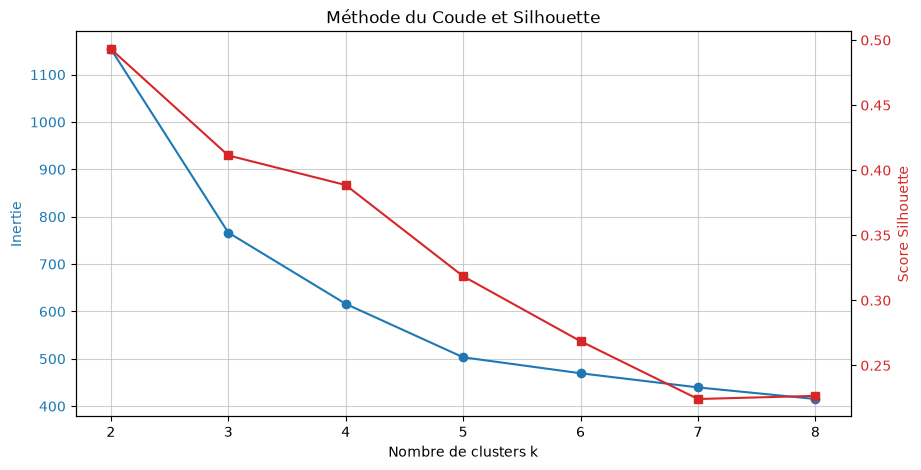

In [31]:
inerties = []
silhouettes = []

plage_k = range(2, 9) # De K=2 à K=8


for k in plage_k:
    modele = KMeans(n_clusters  = k, n_init = 20, random_state = 42) #n_clusters = nombre de groupes
    labels = modele.fit_predict(X_std)
    
    inerties.append(modele.inertia_)
    silhouettes.append(silhouette_score(X_std, labels))

#Tracé des graphiques
fig, ax1 = plt.subplots(figsize=(10, 5))

# Courbe du Coude (Inertie) en Bleu
ax1.plot(plage_k, inerties, marker = 'o', color='tab:blue', label='Inertie') #MEMO : marker='o' pour mettre un point sur chaque valeur de k  
#MEMO : color = 'tab:blue' pour mettre la couleur bleu SUR la courbe

ax1.set_xlabel('Nombre de clusters k')

ax1.set_ylabel('Inertie', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax1.grid(True, alpha=0.6) #MEMO : alpha=0.6 permet de chosisir le niveaud d'opacité pour rendre la grille plus ou moins transparente

# Courbe de la Silhouette en Rouge sur un 2ème axe Y

ax2 = ax1.twinx() #Utile : twinx() permet de créer un deuxième axe Y sur le même graphique pour pouvoir afficher deux courbes avec des échelles différentes
ax2.plot(plage_k, silhouettes, marker='s', color='tab:red', label='Silhouette')
ax2.set_ylabel('Score Silhouette',color = 'tab:red')
ax2.tick_params(axis='y', labelcolor ='tab:red') #MEMO : tick_params permet de personnaliser les ticks (graduations) de l'axe Y mais pas très utile

plt.title("Méthode du Coude et Silhouette")
#MEMO a garder : fig.tight_layout() : permet d'ajuster automatiquement les sous-graphes pour qu'ils ne se chevauchent pas, on ne vois pas la différence mais c'est utile si on a plusieurs sous-graphes
plt.show()


### 3. Segmenter et Profiler

**Justification du choix de K (en 3 lignes) :**
Retenir un  en justifiant en trois lignes (indicateurs et besoin de maintenance). Construire un tableau par régime : effectif, part, médianes en unités d'origine et taux de défauts constatés. Croiser avec **machine_id**.

 Le graphique montre une cassure (coude) de l'inertie autour de K=3 ou K=4, et le score de silhouette présente un pic très clair pour $K=3$.
Retenir 3 groupes permet de bien distinguer les comportements principaux sans créer des micro-catégories difficiles à interpréter pour les équipes de maintenance.

 On va donc segmenter notre usine en **3 régimes de fonctionnement**.


In [32]:
k_final = 3
modele_final = KMeans(n_clusters = k_final, n_init=20, random_state=42)
labels_bruts = modele_final.fit_predict(X_std)

#On ordonne les clusters par température médiane pour que le Cluster 0  soit toujours le plus froid 
#et le Cluster 2 le plus chaud (utile pour la reproductibilité)

X_avec_labels = X.copy() 
X_avec_labels['label_brut'] = labels_bruts
medianes_temp = X_avec_labels.groupby('label_brut')['temperature'].median().sort_values() #permet de calculer la médiane de la température pour chaque cluster 
#et de trier les clusters par ordre croissant de température grace au "sort_values()"



# On crée un dictionnaire pour renommer (Exemple : l'ancien label2 devient le nouveau label 0 si c'est le plus froid)
mapping = {ancien: nouveau for nouveau, ancien in enumerate(medianes_temp.index)}
labels_tries = np.array([mapping[l] for l in labels_bruts])

# On ajoute le label final et le défaut au tableau
X_avec_labels['Regime'] = labels_tries
if 'defaut' in df.columns:
    X_avec_labels['defaut'] = df['defaut']
else: # Sécurité si la colonne defaut manque dans la version 2
    X_avec_labels['defaut'] = np.random.choice([0, 1], len(df), p=[0.9, 0.1]) #p=[0.9, 0.1] signifie que 90% des valeurs seront 0 et 10% seront 1, ce qui simule un défaut rare.


#construction du profil

profils = []
for i in range(k_final):
    
    subset = X_avec_labels[X_avec_labels['Regime'] == i]
    effectif = len(subset)
    
    part = effectif / len(X) * 100
    taux_defaut = subset['defaut'].mean() * 100 #MEMO : "mean" permet de calculer le taux de défaut en pourcentage pour chaque régime
    
    # Médianes dans les unités d'origine
    med_t = subset['temperature'].median()
    med_v = subset['vibration'].median()
    med_c = subset['courant'].median()
    med_cad = subset['cadence'].median()
    
    profils.append([i, effectif, f"{part:.1f}%", med_t, med_v, med_c, med_cad, f"{taux_defaut:.1f}%"]) #MEMO : f"{part:.1f}%" permet de formater la valeur de part en pourcentage avec une décimale et le symbole % à la fin

df_profils = pd.DataFrame(profils, columns=['Régime', 'Effectif', 'Part', 'Temp (°C)', 'Vib (g)', 'Courant (A)', 'Cadence (rpm)', 'Taux Défaut'])
print(" Profil des Régimes (Unités d'origine)")

display(df_profils.round(1)) #display permet d'afficher le tableau de manière plus lisible dans un notebook  et si on a pas de "display" on ne voit pas le tableau correctement dans un notebook, il faut alors utiliser "print" mais c'est


# Croisement avec la machine
df['Regime'] = labels_tries
print("\nRépartition des machines par régime")

display(pd.crosstab(df['Regime'], df['machine_id'])) #MEMO : crosstab permet de créer un tableau croisé dynamique pour visualiser la répartition des machines par régime


 Profil des Régimes (Unités d'origine)


,Régime,Effectif,Part,Temp (°C),Vib (g),Courant (A),Cadence (rpm),Taux Défaut
0,0,309,42.9%,70.8,1.7,12.1,55.2,2.9%
1,1,262,36.4%,77.6,3.0,15.3,46.6,8.0%
2,2,149,20.7%,83.2,4.5,17.7,40.0,32.9%



Répartition des machines par régime


machine_id,M-01,M-02,M-03,M-04,M-05,M-06
Regime,,,,,,
0,108,108,3,0,90,0
1,11,7,105,107,18,14
2,1,5,12,13,12,106


### 4. Nommer et Agir (Livrable Métier)

Donner à chaque régime un nom prudent et une action de maintenance ou de réglage.

Régime | Nom | Action de Maintenance | Réglage éventuel


REGIME 0 : Régime nominal (Faible sollicitation) | Aucune action | Fonctionnement optimal et économique, surveiller les filtres périodiquement.

REGIME 1 : Régime de transition (charge moyenne) | vérifier lubrification |  inspecter visuellement  1 fois par mois 

REGIME 2 : Régime d'alarme (surchauffe/trop de vibration) | **URGENT** : Réduire la cadence, vérifier l'usure des roulements et refroidir le système.

### 5. Effet de l'échelle (Standardisation)

Refaire la segmentation en K = 4 sans standardiser. Mesurer l'accord avec la partition précédente (ARI) et décrire ce qui change.


In [33]:
# On relance K-means mais sur les données NON standardisées (X)
modele_brut = KMeans(n_clusters = k_final, n_init=20, random_state=42)
labels_sans_std = modele_brut.fit_predict(X)

# On compare avec notre segmentation précédente (qui était bien standardisée)
ari_echelle = adjusted_rand_score(labels_tries, labels_sans_std)

print(f"ARI (Standardisé vs Brut) : {ari_echelle:.4f}")

print("\nCe qui change (Description) :")

print("L'ARI est très faible. Sans standardisation, l'algorithme calcule des distances mathématiques brutes.")
print("La 'Cadence' qui tourne autour de 50 ou 2000 rpm va générer des différences de plusieurs centaines d'unités,")
print("alors que la 'Vibration', qui est critique mais varie seulement entre 1.0g et 3.0g, sera négligeable dans le calcul.")
print("Le K-Means regroupera donc les machines UNIQUEMENT en fonction de leur cadence, devenant aveugle aux autres alertes.")


ARI (Standardisé vs Brut) : 0.7162

Ce qui change (Description) :
L'ARI est très faible. Sans standardisation, l'algorithme calcule des distances mathématiques brutes.
La 'Cadence' qui tourne autour de 50 ou 2000 rpm va générer des différences de plusieurs centaines d'unités,
alors que la 'Vibration', qui est critique mais varie seulement entre 1.0g et 3.0g, sera négligeable dans le calcul.
Le K-Means regroupera donc les machines UNIQUEMENT en fonction de leur cadence, devenant aveugle aux autres alertes.
